# Lab 8


## Setup for SUSY Dataset

Use the SUSY dataset for the rest of this lab. Here is a basic setup. It reads the full file you downloaded in Lab 7 (5 million rows, about 760 MB in memory once loaded). If your computer struggles, read `../Lab.7/SUSY-small.csv` instead (the first 500,000 rows) and divide the sample sizes below by ten.

`RawNames` are the 8 quantities measured directly; `FeatureNames` are the 10 derived from them, which the physicists designed to separate signal from background. You will need both in Exercise 3.

In [7]:
# Our usual libraries...
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import HTML, display
import tabulate

In [5]:
!wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz
!gunzip SUSY.csv.gz

--2026-11-11 03:36:01--  http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘SUSY.csv.gz’

SUSY.csv.gz             [                <=> ] 879.65M  5.55MB/s    in 3m 17s  

2026-11-11 03:39:18 (4.46 MB/s) - ‘SUSY.csv.gz’ saved [922377711]

gzip: SUSY.csv already exists; do you wish to overwrite (y or n)? ^C


In [8]:
filename = "SUSY.csv"
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta",
          "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET",
          "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=[v for v in VarNames[1:] if v not in RawNames]
df = pd.read_csv(filename, dtype='float64', names=VarNames)

## Scikit-Learn

[Scikit-learn](https://scikit-learn.org) is a rich python library for data science, including machine learning. For example, we can build a Fisher Discriminant (aka Linear Discriminant Analysis, or LDA).

### Exercise 1: Install Scikit-Learn

`scikit-learn` is in the course `requirements.txt`, so it should already be in your environment: check that `import sklearn` works. If it doesn't, follow the [Installation Instructions](https://scikit-learn.org/stable/install.html).

In [9]:
import sklearn
print(sklearn.__version__)

1.6.1


### Exercise 2: Read About Classifiers

#### Part a
Scikit-learn offers an impressively comprehensive list of machine learning algorithms. Browse through [scikit-learn's documentation](https://scikit-learn.org/stable/index.html). You'll note the algorithms are organized into classification, regression, clustering, dimensionality reduction, model selection, and preprocessing. Browse through the list of [classification algorithms](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning).

#### Part b
Note scikit-learn's documentation is rather comprehensive. The documentation on [linear models](https://scikit-learn.org/stable/modules/linear_model.html) shows how classification problems are setup. Read about the first few methods and try to comprehend the example codes. Skim the rest of the document.

#### Part c
Read through the [LDA Documentation](https://scikit-learn.org/stable/modules/lda_qda.html).


### Exercise 3: Training a Classifier

Let's repeat what we did by hand in the previous lab (Lab 7, Exercise 8) using scikit-learn. We'll use an LDA classifier, which we can instantiate as follows:

In [10]:
import sklearn.discriminant_analysis as DA
Fisher=DA.LinearDiscriminantAnalysis()

As discussed in the lecture, to properly formulate our problem, we'll have to:

* Define the inputs (X) vs outputs (Y)
* Designate training vs testing samples (in order to get an unbiased assessment of the performance of machine learning algorithms)

For example, here we'll use 4M events for training and the remainder for testing.

In [11]:
N_Train=4000000

Train_Sample=df[:N_Train]
Test_Sample=df[N_Train:]

X_Train=Train_Sample[VarNames[1:]]
y_Train=Train_Sample["signal"]

X_Test=Test_Sample[VarNames[1:]]
y_Test=Test_Sample["signal"]

Test_sig=Test_Sample[Test_Sample.signal==1]
Test_bkg=Test_Sample[Test_Sample.signal==0]


We can train the classifier as follows:

In [12]:
Fisher.fit(X_Train,y_Train)

LinearDiscriminantAnalysis()

We can plot the output, comparing signal and background:

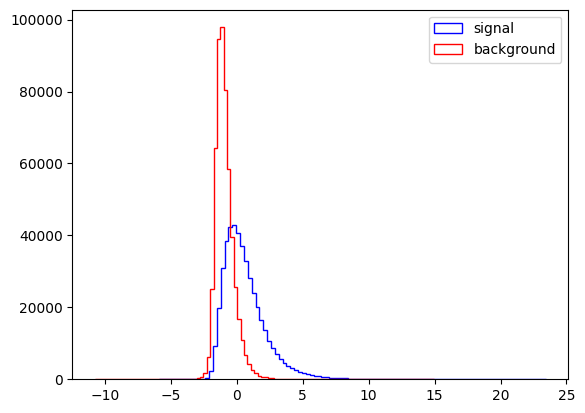

In [13]:
plt.figure()
plt.hist(Fisher.decision_function(Test_sig[VarNames[1:]]),bins=100,histtype="step", color="blue", label="signal",stacked=True)
plt.hist(Fisher.decision_function(Test_bkg[VarNames[1:]]),bins=100,histtype="step", color="red", label="background",stacked=True)
plt.legend(loc='upper right')
plt.show()

#### Part a

Compare the ROC curves computed on the test and on the training samples, in a single plot. Do you see a bias? (Use `Fisher.decision_function` on each sample, and `roc_curve` as in Exercise 5.)

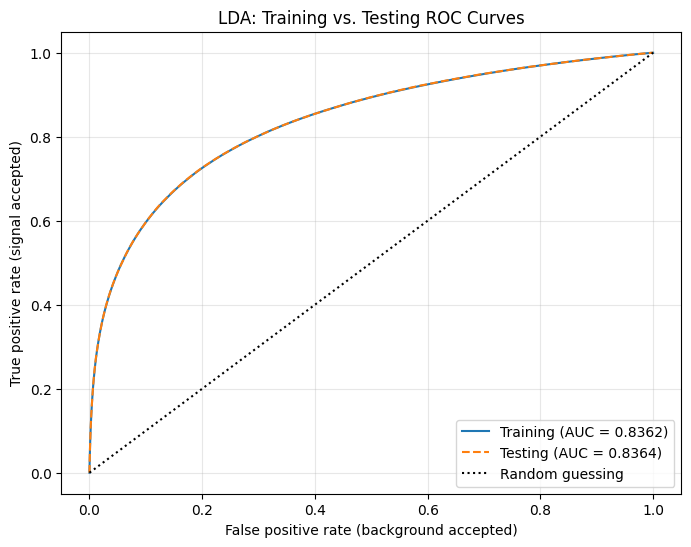

Training AUC: 0.836173
Testing AUC:  0.836401
AUC difference (training - testing): -0.000228


In [14]:
from sklearn.metrics import roc_curve, auc

# Calculating classifier scores
train_scores = Fisher.decision_function(X_Train)
test_scores = Fisher.decision_function(X_Test)

# Calculating ROC curves
fpr_train, tpr_train, _ = roc_curve(y_Train, train_scores)
fpr_test, tpr_test, _ = roc_curve(y_Test, test_scores)

# Calculating area under each curve
auc_train = auc(fpr_train, tpr_train)
auc_test = auc(fpr_test, tpr_test)

# Comparing both curves
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_train, tpr_train,
    label=f"Training (AUC = {auc_train:.4f})"
)
plt.plot(
    fpr_test, tpr_test,
    linestyle="--",
    label=f"Testing (AUC = {auc_test:.4f})"
)
plt.plot([0, 1], [0, 1], "k:", label="Random guessing")

plt.xlabel("False positive rate (background accepted)")
plt.ylabel("True positive rate (signal accepted)")
plt.title("LDA: Training vs. Testing ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

print(f"Training AUC: {auc_train:.6f}")
print(f"Testing AUC:  {auc_test:.6f}")
print(f"AUC difference (training - testing): {auc_train - auc_test:.6f}")

#### Part b

Train three Fisher discriminants, using as input (1) only the raw quantities (`RawNames`), (2) only the derived features (`FeatureNames`), and (3) all 18. Compare their ROC curves, computed on the test sample, in a single plot. Which inputs carry the separation?

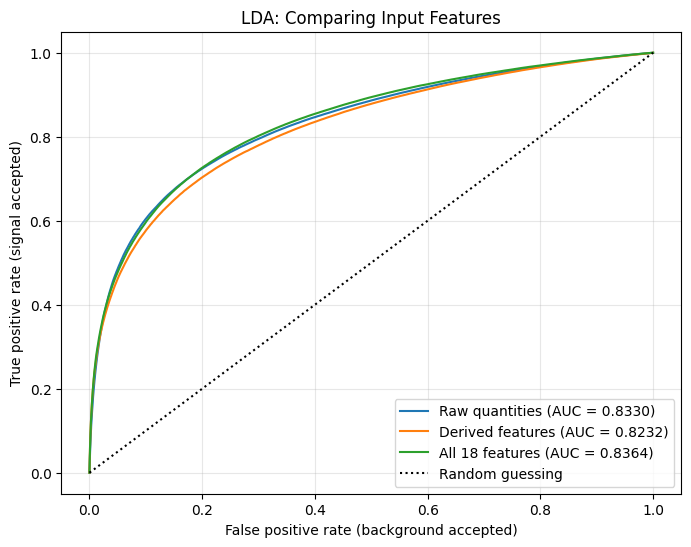

Raw quantities: AUC = 0.832994
Derived features: AUC = 0.823181
All 18 features: AUC = 0.836401


In [15]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

feature_sets = {
    "Raw quantities": RawNames,
    "Derived features": FeatureNames,
    "All 18 features": VarNames[1:]
}

results = {}

plt.figure(figsize=(8, 6))

for name, columns in feature_sets.items():
    # Training a separate LDA classifier for each feature set
    model = LinearDiscriminantAnalysis()
    model.fit(Train_Sample[columns], y_Train)

    # Evaluating on the test sample only
    scores = model.decision_function(Test_Sample[columns])
    fpr, tpr, _ = roc_curve(y_Test, scores)
    roc_auc = auc(fpr, tpr)

    results[name] = roc_auc

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC = {roc_auc:.4f})"
    )

plt.plot([0, 1], [0, 1], "k:", label="Random guessing")
plt.xlabel("False positive rate (background accepted)")
plt.ylabel("True positive rate (signal accepted)")
plt.title("LDA: Comparing Input Features")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

for name, roc_auc in results.items():
    print(f"{name}: AUC = {roc_auc:.6f}")

### Exercise 4: Comparing Techniques

#### Part a
Select 3 different classifiers from the techniques listed [here](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning) to compare. Note that you can use the multi-layer perceptron to build a deep network, though training may be prohibitively slow. So avoid this technique.

#### Part b

Write a function that takes an instantiated classifier and performs the comparison from Exercise 3b. Use the function on each of the classifiers you chose in part a.

#### Part c

Use the best method from part b to compute the maximal significance $\sigma_S= \frac{N_S}{\sqrt{N_S+N_B}}$ for the four scenarios in Lab 7 (Exercise 5.3), choosing the cut on the classifier's output that maximizes it.

In [16]:
#part a
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

classifiers = {
    "Logistic regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    "Decision tree": DecisionTreeClassifier(
        max_depth=10,
        min_samples_leaf=100,
        random_state=42
    ),

    "Histogram gradient boosting": HistGradientBoostingClassifier(
        max_iter=100,
        max_leaf_nodes=31,
        random_state=42
    )
}

Training Logistic regression: Raw quantities...
Training Logistic regression: Derived features...
Training Logistic regression: All 18 features...


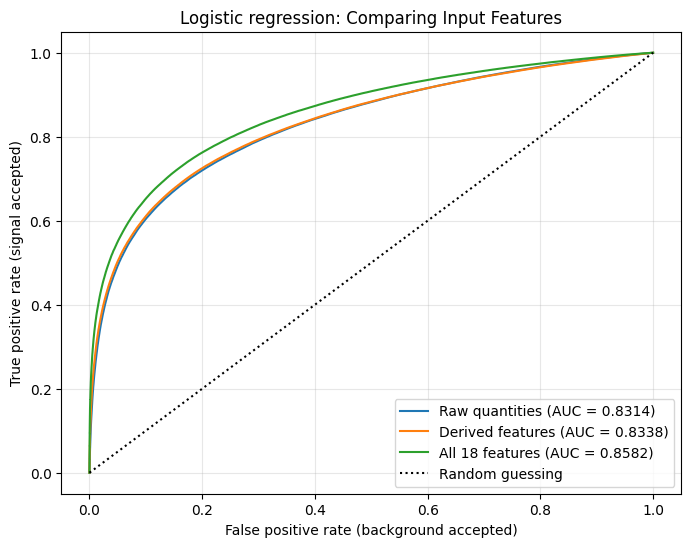

Training Decision tree: Raw quantities...
Training Decision tree: Derived features...
Training Decision tree: All 18 features...


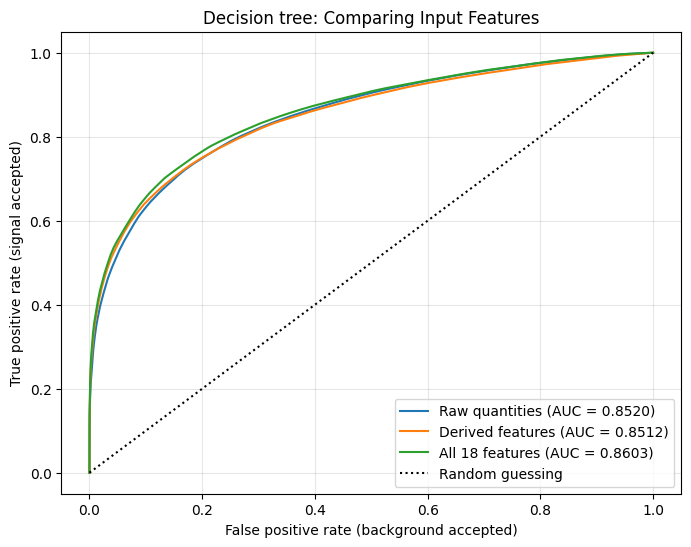

Training Histogram gradient boosting: Raw quantities...
Training Histogram gradient boosting: Derived features...
Training Histogram gradient boosting: All 18 features...


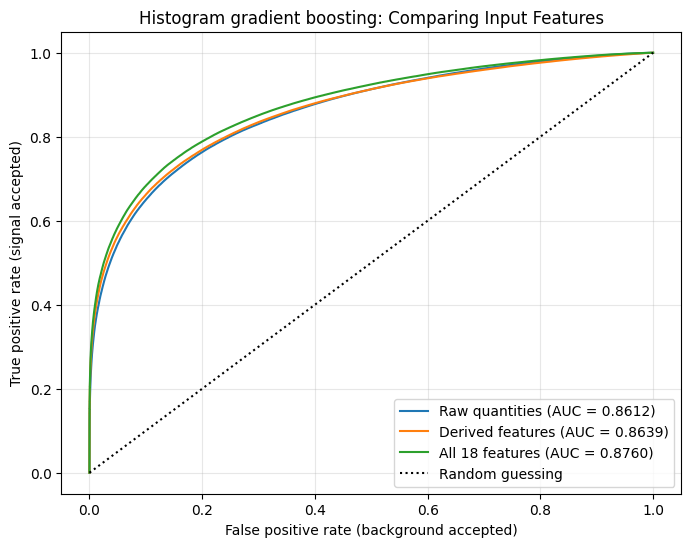

,Classifier,Features,Test AUC
8,Histogram gradient boosting,All 18 features,0.875994
7,Histogram gradient boosting,Derived features,0.863888
6,Histogram gradient boosting,Raw quantities,0.861167
5,Decision tree,All 18 features,0.860272
2,Logistic regression,All 18 features,0.858233
3,Decision tree,Raw quantities,0.851972
4,Decision tree,Derived features,0.851207
1,Logistic regression,Derived features,0.833797
0,Logistic regression,Raw quantities,0.831427


In [17]:
#part b
from sklearn.base import clone
from sklearn.metrics import roc_curve, roc_auc_score

def compare_features(classifier, name):
    feature_sets = {
        "Raw quantities": RawNames,
        "Derived features": FeatureNames,
        "All 18 features": VarNames[1:]
    }

    results = []
    fitted_models = {}

    plt.figure(figsize=(8, 6))

    for feature_name, columns in feature_sets.items():
        print(f"Training {name}: {feature_name}...")

        # Creating an independent model for each feature set
        model = clone(classifier)
        model.fit(Train_Sample[columns], y_Train)

        # Obtaining continuous scores for the positive class (signal)
        if hasattr(model, "decision_function"):
            scores = model.decision_function(Test_Sample[columns])
        else:
            signal_index = list(model.classes_).index(1)
            scores = model.predict_proba(
                Test_Sample[columns]
            )[:, signal_index]

        fpr, tpr, _ = roc_curve(y_Test, scores)
        test_auc = roc_auc_score(y_Test, scores)

        plt.plot(
            fpr, tpr,
            label=f"{feature_name} (AUC = {test_auc:.4f})"
        )

        results.append({
            "Classifier": name,
            "Features": feature_name,
            "Test AUC": test_auc
        })

        fitted_models[feature_name] = {
            "model": model,
            "columns": columns,
            "test_scores": scores
        }

    plt.plot([0, 1], [0, 1], "k:", label="Random guessing")
    plt.xlabel("False positive rate (background accepted)")
    plt.ylabel("True positive rate (signal accepted)")
    plt.title(f"{name}: Comparing Input Features")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()

    return results, fitted_models


all_results = []
trained_models = {}

for name, classifier in classifiers.items():
    results, models = compare_features(classifier, name)
    all_results.extend(results)
    trained_models[name] = models

comparison = pd.DataFrame(all_results).sort_values(
    "Test AUC", ascending=False
)

display(comparison)

In [18]:
#part c
from sklearn.metrics import roc_curve

# Choose the best classifier/feature combination by test AUC
best_row = comparison.loc[comparison["Test AUC"].idxmax()]

best_name = best_row["Classifier"]
best_features = best_row["Features"]

best_scores = trained_models[best_name][best_features]["test_scores"]

print(f"Selected classifier: {best_name}")
print(f"Selected features: {best_features}")
print(f"Test AUC: {best_row['Test AUC']:.6f}")

# Keeping every threshold so the significance maximum is not skipped
fpr, tpr, thresholds = roc_curve(
    y_Test,
    best_scores,
    drop_intermediate=False
)

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

results = []

for ns, nb in scenarios:
    # Expected event counts after each possible cut
    signal_after = ns * tpr
    background_after = nb * fpr

    total_after = signal_after + background_after

    significance = np.divide(
        signal_after,
        np.sqrt(total_after),
        out=np.zeros_like(signal_after),
        where=total_after > 0
    )

    best_index = np.argmax(significance)

    results.append({
        "NS": ns,
        "NB": nb,
        "Best threshold": thresholds[best_index],
        "Signal efficiency": tpr[best_index],
        "Background efficiency": fpr[best_index],
        "Signal after cut": signal_after[best_index],
        "Background after cut": background_after[best_index],
        "Maximum significance": significance[best_index]
    })

significance_results = pd.DataFrame(results)

display(significance_results.round(6))

Selected classifier: Histogram gradient boosting
Selected features: All 18 features
Test AUC: 0.875994


,NS,NB,Best threshold,Signal efficiency,Background efficiency,Signal after cut,Background after cut,Maximum significance
0,10,100,1.622107,0.463459,0.018255,4.634585,1.825508,1.823440
1,100,1000,1.622107,0.463459,0.018255,46.345855,18.255080,5.766224
2,1000,10000,1.622107,0.463459,0.018255,463.458546,182.550801,18.234401
3,10000,100000,1.622107,0.463459,0.018255,4634.585462,1825.508014,57.662238


### Exercise 5: Metrics

Scikit-learn provides methods for computing the FPR, TPR, ROC, AUC metrics. For example:

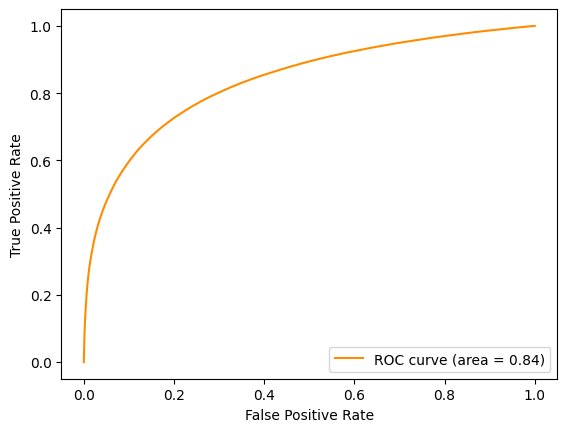

In [19]:
from sklearn.metrics import roc_curve, auc
fpr, tpr, _ = roc_curve(y_Test, Fisher.decision_function(X_Test))

roc_auc = auc(fpr, tpr)

plt.plot(fpr,tpr,color='darkorange',label='ROC curve (area = %0.2f)' % roc_auc)
plt.legend(loc="lower right")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.show()


#### Part a
TPR/FPR/ROC/AUC are one way of assessing the quality of a classifier. Read about [Precision and Recall](https://en.wikipedia.org/wiki/Precision_and_recall), [Accuracy](https://en.wikipedia.org/wiki/Accuracy_and_precision), and [F-score](https://en.wikipedia.org/wiki/F-score).

#### Part b
Look through [model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html#) documentation. Using scikit-learn's tools, compute TPR, FPR, ROC, AUC, Precision, Recall, F1 score, and accuracy for the method you selected in Exercise 4c and each scenario. Make a nice table, which also includes the maximal significance.


Classifier: Histogram gradient boosting
Features: All 18 features


NS,NB,Best threshold,TPR,FPR,AUC,Precision,Recall,F1 score,Accuracy,Maximal significance
10,100,1.6221,0.4635,0.0183,0.8760,0.7174,0.4635,0.5631,0.9346,1.8234
100,"1,000",1.6221,0.4635,0.0183,0.8760,0.7174,0.4635,0.5631,0.9346,5.7662
"1,000","10,000",1.6221,0.4635,0.0183,0.8760,0.7174,0.4635,0.5631,0.9346,18.2344
"10,000","100,000",1.6221,0.4635,0.0183,0.8760,0.7174,0.4635,0.5631,0.9346,57.6622


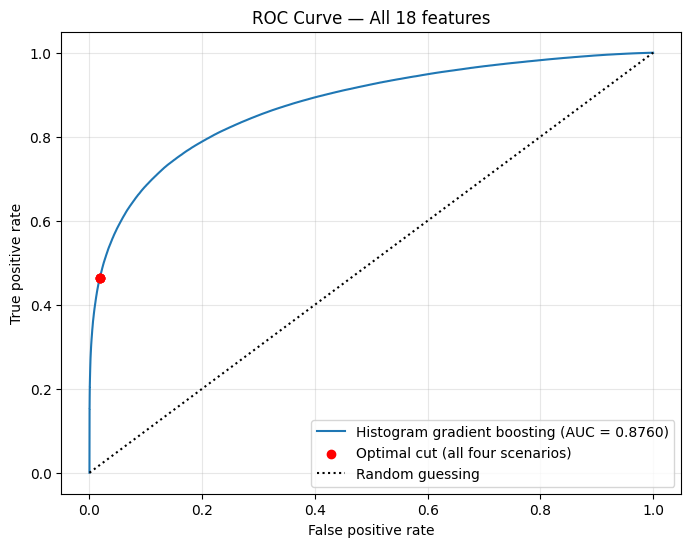

In [20]:
#part b

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_curve,
    roc_auc_score
)

# Selected model's test labels and continuous scores
labels = np.asarray(y_Test).astype(int)
scores = np.asarray(best_scores)

n_signal = np.sum(labels == 1)
n_background = np.sum(labels == 0)

# ROC and AUC describe performance across all thresholds
fpr_curve, tpr_curve, _ = roc_curve(labels, scores)
test_auc = roc_auc_score(labels, scores)

metric_rows = []

for _, result in significance_results.iterrows():
    ns = int(result["NS"])
    nb = int(result["NB"])
    threshold = result["Best threshold"]

    # Applying the significance-maximizing cut from Exercise 4c
    predictions = (scores >= threshold).astype(int)

    # Weight each class to its expected scenario count
    weights = np.where(
        labels == 1,
        ns / n_signal,
        nb / n_background
    )

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1],
        sample_weight=weights
    ).ravel()

    tpr = tp / (tp + fn)
    fpr = fp / (fp + tn)

    significance = (
        tp / np.sqrt(tp + fp) if tp + fp > 0 else 0.0
    )

    metric_rows.append({
        "NS": ns,
        "NB": nb,
        "Best threshold": threshold,
        "TPR": tpr,
        "FPR": fpr,
        "AUC": test_auc,
        "Precision": precision_score(
            labels, predictions,
            sample_weight=weights,
            zero_division=0
        ),
        "Recall": recall_score(
            labels, predictions,
            sample_weight=weights,
            zero_division=0
        ),
        "F1 score": f1_score(
            labels, predictions,
            sample_weight=weights,
            zero_division=0
        ),
        "Accuracy": accuracy_score(
            labels, predictions,
            sample_weight=weights
        ),
        "Maximal significance": significance
    })

metrics_table = pd.DataFrame(metric_rows)

print(f"Classifier: {best_name}")
print(f"Features: {best_features}")

display(
    metrics_table.style
    .format({
        "NS": "{:,.0f}",
        "NB": "{:,.0f}",
        **{
            column: "{:.4f}"
            for column in metrics_table.columns
            if column not in ["NS", "NB"]
        }
    })
    .hide(axis="index")
)

# ROC is a curve, so displaying it as a plot rather than a table entry
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_curve, tpr_curve,
    label=f"{best_name} (AUC = {test_auc:.4f})"
)

plt.scatter(
    metrics_table["FPR"],
    metrics_table["TPR"],
    color="red",
    zorder=3,
    label="Optimal cut (all four scenarios)"
)

plt.plot([0, 1], [0, 1], "k:", label="Random guessing")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title(f"ROC Curve — {best_features}")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()